# hydrophobic interactions

In [2]:
import warnings
warnings.filterwarnings('ignore')

import os
import sys
import shutil
import glob
import logging
import xml.etree.ElementTree as ET

from pathlib import Path
from io import StringIO
from typing import Dict, List, Optional, Union
from functools import reduce
import multiprocess as mp
from multiprocessing import cpu_count

import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm
from tqdm.contrib.logging import logging_redirect_tqdm
import logging

import parmed as pmd
from openbabel import openbabel

from rdkit import Chem
from rdkit.Chem import rdmolops, AllChem, Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

from plip.structure.preparation import PDBComplex, logger as PLIP_LOGGER
from plip.exchange.report import StructureReport
from plip.basic import config as PLIP_CONFIG

PLIP_LOGGER.setLevel(logging.ERROR)
PLIP_LOGGER.propagate = False

In [ ]:
cwdir = os.getcwd()
dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'
subdirs = ['biolip2_opt/',
           'pdbbind_opt_poly/',
           'pdbbind_opt_sm/']

def generate_PDBIDs():
    fcsv = os.path.join(dataset_dir, 'PDBIDs.csv')
    df_PDBIDs = pd.read_csv(fcsv)
    PDBIDs = (df_PDBIDs.T).to_numpy()
    PDBIDs = PDBIDs.tolist()
    PDBIDs = [[x for x in row if x is not None and not (isinstance(x, float) and math.isnan(x))]for row in PDBIDs]
    return PDBIDs

def generate_args():
    args = []
    for index, subdir in enumerate(subdirs):
        for PDBID in PDBIDs[index]:
            args.append((
                PDBID,
                subdir,
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_ligand_refined.sdf'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_ligand_refined.pdb'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_protein_refined.pdb'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/{PDBID}_complex.pdb'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/interaction.xml'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/HydrophobicProteinFragment'),
                os.path.join(dataset_dir, f'{subdir}{PDBID[:4]}/{PDBID}/HydrophobicLigandFragment')
            ))
    return args

PDBIDs = generate_PDBIDs()
args = generate_args()

In [87]:
def extract_hydrophobic(xmlpath):
    xmlobj = ET.parse(xmlpath)
    binding_sites = xmlobj.findall("./bindingsite")
    bs = [bs for bs in binding_sites if bs.findall("identifiers/longname")[0].text == "UNL"][0]
    hydrophobics = bs.findall("interactions/hydrophobic_interactions/hydrophobic_interaction")
    infos = []
    for hydrophobic in hydrophobics:
        info = {}
        for attr in hydrophobic:
            if attr.tag == 'ligcoo' or attr.tag == 'protcoo':
                for s in ['x', 'y', 'z']:
                    info[f'{attr.tag}_{s}'] = attr.find(s).text
            else:
                info[attr.tag] = attr.text
        infos.append(info)
    return infos

def make_identifier(code, resnr, restype, ligcarbonidx, protcarbonidx):
    return f'{code}_{resnr}_{restype}_{ligcarbonidx}_{protcarbonidx}'

def make_identifier_from_row(row):
    return make_identifier(row['full_PDBID'], row['resnr'], row['restype'], row['ligcarbonidx'], row['protcarbonidx'])

In [88]:
df = []
errs = []

for arg in tqdm(args):
    try:
        infos = extract_hydrophobic(arg[6])
        for info in infos:
            info['PDBID'] = arg[0][:4]
            info['full_PDBID'] = arg[0]
            info['subdir'] = arg[1]
            df.append(info)
    except Exception as e:
        errs.append((arg[0], e))

print(len(errs))
df = pd.DataFrame(df)
cols = ['PDBID'] + ['full_PDBID'] + ['subdir'] + list(df.columns[:-3])
df = df[cols]

df.index = [make_identifier_from_row(row) for index, row in df.iterrows()]
fcsv = os.path.join(cwdir, 'hydrophobic.csv')
df.to_csv(fcsv)
df

100%|██████████| 18928/18928 [00:13<00:00, 1397.69it/s]


0


,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,dist,ligcarbonidx,protcarbonidx,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z
182l_BZF_A_401_79_ILE_6_1245,182l,182l_BZF_A_401,biolip2_opt/,79,ILE,A,1,UNL,Z,3.99,6,1245,26.064,6.048,6.006,27.707,5.572,9.615
182l_BZF_A_401_85_LEU_6_1344,182l,182l_BZF_A_401,biolip2_opt/,85,LEU,A,1,UNL,Z,3.86,6,1344,26.064,6.048,6.006,22.460,6.865,7.112
182l_BZF_A_401_88_VAL_8_1401,182l,182l_BZF_A_401,biolip2_opt/,88,VAL,A,1,UNL,Z,3.61,8,1401,26.191,4.950,3.893,24.289,3.236,1.345
182l_BZF_A_401_89_TYR_7_1415,182l,182l_BZF_A_401,biolip2_opt/,89,TYR,A,1,UNL,Z,3.74,7,1415,25.706,5.021,5.157,24.929,1.811,6.914
182l_BZF_A_401_100_ALA_4_1584,182l,182l_BZF_A_401,biolip2_opt/,100,ALA,A,1,UNL,Z,3.58,4,1584,27.420,7.012,4.348,29.645,4.445,5.470
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9hvp_0E9_A_100_128_ALA_43_2122,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,128,ALA,B,1,UNL,Z,3.50,43,2122,-10.599,15.507,23.407,-11.102,18.895,22.682
9hvp_0E9_A_100_147_ILE_44_2438,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,147,ILE,B,1,UNL,Z,3.53,44,2438,-8.755,15.111,21.691,-9.059,12.204,19.706
9hvp_0E9_A_100_150_ILE_37_2467,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,150,ILE,B,1,UNL,Z,3.99,37,2467,-5.569,17.777,27.680,-4.557,14.845,30.197
9hvp_0E9_A_100_181_PRO_29_2949,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,181,PRO,B,1,UNL,Z,3.62,29,2949,-13.033,12.300,29.488,-13.647,9.139,27.835


In [55]:
hydrophobic_dir = os.getcwd()
dataset_dir = '/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset'
subdirs = ['biolip2_opt/',
            'pdbbind_opt_poly/',
            'pdbbind_opt_sm/']


df = pd.read_csv("hydrophobic.csv", index_col=0)

def interactions(df):
    interactions = []
    for index, row in tqdm(df.iterrows()):
        interactions.append((
            row['PDBID'], 
            row['full_PDBID'],
            row['subdir'],
            os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_complex.pdb"),
            os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/interaction.xml"),
            os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HydrophobicProteinFragment"),
            os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HydrophobicLigandFragment"), 
            os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf"),
            index,
            row['restype'], 
            row['resnr'], 
            row['reschain']
        ))
    return interactions

hydrophobics = interactions(df)

86267it [00:02, 28904.45it/s]


# Carbon-Based Fragmentation Code

In [57]:
from rdkit import Chem
from openbabel import openbabel

hydrophobic_dir = os.getcwd()
os.chdir('../')
from edautils.fragment import find_rings
os.chdir(hydrophobic_dir)


def frag(mol, idx, R, n=2, dist_cutoff=6.0): # R: coordinate of carbon_idx on other fragment
    """
    carbon based recursive hydrophobic interaction fragment algorithm

    Args:
        mol: rdkit.Chem.rdchem.Mol
            ligand/protein molecule
        idx: int
            carbon index on mol
        R: list
            coordinates of carbon index on other fragment
        n: int
            number of branches
        dist_cutoff: double
            distance cutoff from caerbon index of molecule to farthest atom
    Returns: 
        atom: set
            list of atom idx included in the fragment
    """
    idx = int(idx) - 1 # shift index for RDkit
    rings = find_rings(mol, merge_rings=True, find_hetero_rings=False, find_small_rings=False) # find aromatic rings only
    
    conf = mol.GetConformer()

    visited = set([idx])
    visited_rings = set()
    atoms = set([idx])

    def neighbor(idx, depth):
        if depth >= n:
            return
        
        atom = mol.GetAtomWithIdx(idx)
        for nbr in atom.GetNeighbors():

            nbr_pos = conf.GetAtomPosition(nbr.GetIdx())
            nbr_R = np.array([nbr_pos.x, nbr_pos.y, nbr_pos.z])
            dist = np.linalg.norm(nbr_R - R)
            # print([nbr.GetIdx(), dist])

            if nbr.GetIdx() in visited or (dist > dist_cutoff):
                continue
            elif nbr.GetSymbol() == 'H':
                atoms.add(nbr.GetIdx())
                continue
            elif nbr.GetSymbol() == 'C':
                visited.add(nbr.GetIdx())
                atoms.add(nbr.GetIdx())
            else:
                visited.add(nbr.GetIdx())
                continue

            for bond in nbr.GetBonds():
                if bond.GetBondType() in (Chem.BondType.DOUBLE, Chem.BondType.TRIPLE):
                    for b_atom in (bond.GetBeginAtom(), bond.GetEndAtom()):
                        b_idx = b_atom.GetIdx()
                        visited.add(b_idx)
                        atoms.add(b_idx)


            for r in rings: # Check if carbon atom in aromatic ring
                visited_rings.update(r)
                if nbr.GetIdx() in r:
                    for i in r:
                        visited.add(i)
                        atoms.add(i)
            neighbor(nbr.GetIdx(), depth + 1)

    neighbor(idx, 0)
    atoms = [id + 1 for id in atoms]
    return sorted(atoms)



In [60]:
frags = []
for index, row in tqdm(df[162:183].iterrows()):
    ligand = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf")
    mol = Chem.SDMolSupplier(ligand, removeHs=False, sanitize=True)[0]
    R = [row['protcoo_x'], row['protcoo_y'], row['protcoo_z']]
    atomidx = frag(mol, row['ligcarbonidx'], R, n=2, dist_cutoff=6.0)
    
    fragment = select_fragment(mol, atomidx)
    fragment.SetProp("identifier", arg[8])

    lig_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HydrophobicLigandFragment")
    if not os.path.isdir(lig_frag_dir):
        os.mkdir(lig_frag_dir)
    write_sdf(fragment, os.path.join(lig_frag_dir, f'{index}.sdf'))

    frag_no_h = Chem.RemoveHs(fragment)
    AllChem.Compute2DCoords(frag_no_h)
    frags.append(frag_no_h)

21it [00:00, 348.92it/s]


In [62]:
multi_frags = []

for index, row in tqdm(df[162:183].iterrows()):
    lig_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HydrophobicLigandFragment")
    ligand = os.path.join(lig_frag_dir, f"{index}.sdf")
    mol = Chem.SDMolSupplier(ligand, removeHs=False, sanitize=True)[0]
    lig_frags = Chem.GetMolFrags(mol, asMols=False)
    
    if len(lig_frags) > 1:
        multi_frags.append((index, lig_frags))

multi_frags

21it [00:00, 2092.27it/s]


[('1fap_RAP_A_108_27_TYR_7_532',
  ((0, 1, 2, 4, 5, 6, 7, 9, 10, 11), (3, 12), (8, 13))),
 ('1fap_RAP_A_108_37_PHE_56_688',
  ((0, 8, 9),
   (1, 2, 4, 10, 11, 12, 13, 14),
   (3, 7, 15, 16, 17),
   (5, 18),
   (6, 19))),
 ('1fap_RAP_A_108_47_PHE_7_856',
  ((0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13), (9, 14))),
 ('1fap_RAP_A_108_47_PHE_6_854',
  ((0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 13), (4, 14))),
 ('1fap_RAP_A_108_57_ILE_55_1024',
  ((0, 1, 3, 5, 7, 8, 10, 11, 12, 13, 16),
   (2, 14, 15),
   (4, 9, 17, 18, 19),
   (6, 20))),
 ('1fap_RAP_A_108_60_TRP_5_1075',
  ((0, 11, 12), (1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 13, 14, 15, 16, 17, 18, 19))),
 ('1fap_RAP_A_108_83_TYR_46_1425',
  ((0, 1, 2, 3, 5, 6, 7, 8, 12, 13, 14, 15, 16, 17),
   (4, 11, 18, 19, 20),
   (9, 21),
   (10, 22))),
 ('1fap_RAP_A_108_91_ILE_56_1524',
  ((0, 8, 9),
   (1, 2, 4, 10, 11, 12, 13, 14),
   (3, 7, 15, 16, 17),
   (5, 18),
   (6, 19))),
 ('1fap_RAP_A_108_92_ILE_56_1536',
  ((0, 1, 3, 7, 8, 9, 10, 11), (2, 6, 12, 13,

In [ ]:
for index, row in df[162:183].iterrows():
    ligand = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf")
    mol = Chem.SDMolSupplier(ligand, removeHs=False, sanitize=True)[0]
    R = [row['protcoo_x'], row['protcoo_y'], row['protcoo_z']]
    print((frag(mol, row['ligcarbonidx'], R, n=2, dist_cutoff=6.0), index))


([6, 7, 8, 69, 70, 71, 72, 73, 74], '1fap_RAP_A_108_27_TYR_7_532')
([14, 17, 18, 56, 76, 115, 116, 117], '1fap_RAP_A_108_37_PHE_56_688')
([5, 6, 7, 8, 69, 70, 71, 72, 73, 74], '1fap_RAP_A_108_47_PHE_7_856')
([5, 6, 7, 8, 67, 68, 69, 70, 71, 72], '1fap_RAP_A_108_47_PHE_6_854')
([4, 5, 6, 7, 8, 67, 68, 69, 70, 71, 72], '1fap_RAP_A_108_56_VAL_6_1005')
([47, 48, 52, 54, 55, 105, 111, 112, 113, 114], '1fap_RAP_A_108_57_ILE_55_1024')
([4, 5, 6, 7, 8, 67, 68, 69, 70, 71, 72], '1fap_RAP_A_108_60_TRP_6_1080')
([1, 3, 4, 5, 6, 7, 66, 67, 68, 69, 70], '1fap_RAP_A_108_60_TRP_5_1075')
([45, 46, 47, 48, 62, 101, 102, 103, 104, 133, 134, 135], '1fap_RAP_A_108_83_TYR_46_1425')
([14, 17, 18, 56, 76, 115, 116, 117], '1fap_RAP_A_108_91_ILE_56_1524')
([17, 18, 56, 76, 115, 116, 117], '1fap_RAP_A_108_92_ILE_56_1536')
([30, 58, 90, 121, 122, 123], '1fap_RAP_A_108_122_LEU_58_2045')
([22, 24, 25, 26, 27, 85, 86], '1fap_RAP_A_108_130_PHE_25_2191')
([45, 46, 47, 62, 102, 133, 134, 135], '1fap_RAP_A_108_130_PHE_

# Protein Carbon Atom Name

In [30]:
def wrapper_protcarbonname(arg):
    index, row = arg
    try:
        complex = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_complex.pdb")
        structure = pmd.load_file(complex)
        residues = structure[f":{row['resnr']}"].residues
        number_to_atom = {atom.number: atom for atom in structure.atoms}
        protcarbon = number_to_atom[int(row['protcarbonidx'])]

        if protcarbon.name in ['C', 'CA']:
            sidechain = False
        else:
            sidechain = True

        return index, protcarbon.name, sidechain, None
    
    except Exception as e:
        return index, None, None, str(e)

    
args = [(idx, row.to_dict()) for idx, row in df.iterrows()]
results = []

with mp.Pool(cpu_count()) as pool:
    for res in tqdm(pool.imap(wrapper_protcarbonname, args), total=len(args)):
        results.append(res)

# fill dataframe
errs = []
for index, protcarbonname, sidechain, err in results:
    if err is None:
        df.loc[index, "protcarbonname"] = protcarbonname
        df.loc[index, "sidechain"] = sidechain
    else:
        errs.append((index, err))


  0%|          | 193/86267 [00:10<1:24:49, 16.91it/s]2025-09-22 02:54:59,515 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, which could lead to extra TER cards in a PDB file
2025-09-22 02:54:59,560 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, which could lead to extra TER cards in a PDB file
2025-09-22 02:54:59,825 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, which could lead to extra TER cards in a PDB file
2025-09-22 02:54:59,905 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, which could lead to extra TER cards in a PDB file
2025-09-22 02:54:59,918 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, wh

In [35]:
df.to_csv('hydrophobic.csv')
print(len(errs))
df

0


,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,dist,ligcarbonidx,protcarbonidx,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z,protcarbonname,sidechain
182l_BZF_A_401_79_ILE_6_1245,182l,182l_BZF_A_401,biolip2_opt/,79,ILE,A,1,UNL,Z,3.99,6,1245,26.064,6.048,6.006,27.707,5.572,9.615,CD1,True
182l_BZF_A_401_85_LEU_6_1344,182l,182l_BZF_A_401,biolip2_opt/,85,LEU,A,1,UNL,Z,3.86,6,1344,26.064,6.048,6.006,22.460,6.865,7.112,CB,True
182l_BZF_A_401_88_VAL_8_1401,182l,182l_BZF_A_401,biolip2_opt/,88,VAL,A,1,UNL,Z,3.61,8,1401,26.191,4.950,3.893,24.289,3.236,1.345,CG1,True
182l_BZF_A_401_89_TYR_7_1415,182l,182l_BZF_A_401,biolip2_opt/,89,TYR,A,1,UNL,Z,3.74,7,1415,25.706,5.021,5.157,24.929,1.811,6.914,CB,True
182l_BZF_A_401_100_ALA_4_1584,182l,182l_BZF_A_401,biolip2_opt/,100,ALA,A,1,UNL,Z,3.58,4,1584,27.420,7.012,4.348,29.645,4.445,5.470,CB,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9hvp_0E9_A_100_128_ALA_43_2122,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,128,ALA,B,1,UNL,Z,3.50,43,2122,-10.599,15.507,23.407,-11.102,18.895,22.682,CB,True
9hvp_0E9_A_100_147_ILE_44_2438,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,147,ILE,B,1,UNL,Z,3.53,44,2438,-8.755,15.111,21.691,-9.059,12.204,19.706,CD1,True
9hvp_0E9_A_100_150_ILE_37_2467,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,150,ILE,B,1,UNL,Z,3.99,37,2467,-5.569,17.777,27.680,-4.557,14.845,30.197,CG2,True
9hvp_0E9_A_100_181_PRO_29_2949,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,181,PRO,B,1,UNL,Z,3.62,29,2949,-13.033,12.300,29.488,-13.647,9.139,27.835,CG,True


In [37]:
df.query('sidechain == False')

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,dist,ligcarbonidx,protcarbonidx,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z,protcarbonname,sidechain
1mmp_RSS_B_269_83_LEU_20_1366,1mmp,1mmp_RSS_B_269,pdbbind_opt_sm/,83,LEU,B,1,UNL,Z,3.73,20,1366,8.526,45.591,65.884,6.197,42.686,65.640,C,False
5oci_9R8_A_301_89_ILE_28_1455,5oci,5oci_9R8_A_301,pdbbind_opt_sm/,89,ILE,A,1,UNL,Z,2.50,28,1455,72.373,32.758,22.838,73.931,33.225,20.933,CA,False
5w85_9YS_A_4000_35_GLY_6_553,5w85,5w85_9YS_A_4000,pdbbind_opt_sm/,35,GLY,A,1,UNL,Z,3.57,6,553,8.920,44.916,14.821,8.881,48.333,15.864,CA,False


In [56]:
backbone = ['1mmp_RSS_B_269_83_LEU_20_1366', '5oci_9R8_A_301_89_ILE_28_1455', '5w85_9YS_A_4000_35_GLY_6_553']

# Fragment Protein

In [57]:
hydrophobic_res = ['MET', 'LEU', 'VAL', 'ILE', 'PRO', 'ALA', 'PHE']
hydrophillic_res = ['HIS', 'TRP', 'ASN', 'GLN', 'TYR', 'THR']
charged_res = ['GLU', 'ASP', 'LYS', 'ARG'] # kick HIP


FRAG_SIDE_CHAIN = {
    # hydrophobic
    'MET': ['CA', 'HA', 'CB', 'HB2', 'HB3', 'CG', 'HG2', 'HG3', 'SD', 'CE', 'HG1', 'HG2', 'HE3'],
    'LEU': ['CA', 'HA', 'CB', 'HB2', 'HB3', 'CG', 'HG', 'CD1', 'HD11', 'HD12', 'HD13', 'CD2', 'HD21', 'HD22', 'HD23'],
    'VAL': ['CA', 'HA', 'CB', 'HB', 'CG1', 'HG11', 'HG12', 'HG13', 'CG2', 'HG21', 'HG22', 'HG23'],
    'ILE': ['CA', 'HA', 'CB', 'HB', 'CG1', 'HG12', 'HG13', 'CG2', 'HG21', 'HG22', 'HG23', 'CD1', 'HD11', 'HD12', 'HD13'],
    'PRO': ['N', 'CA', 'HA', 'CB', 'HB2', 'HB3', 'CG', 'HG2', 'HG3', 'CD', 'HD2', 'HD3'],
    'ALA': ['CA', 'CB', 'HB1', 'HB2', 'HB3'],
    'PHE': ['CA', 'HA', 'CB', 'HB1', 'HB2', 'CG', 'CD1', 'HD1', 'CD2', 'HD2', 'CE1', 'HE1', 'CE2', 'HE2', 'CZ', 'HZ'],
        
    #charged
    'ASP': ['CA', 'HA', 'CB', 'HB2', 'HB3'],
    'GLU': ['CA', 'HA', 'CB', 'HB2', 'HB3', 'CG', 'HG2', 'HG3'],
    'LYS': ['CA', 'HA', 'CB', 'HB2', 'HB3', 'CG', 'HG2', 'HG3', 'CD', 'HD2', 'HD3', 'CE', 'HE2', 'HE3'],
    'ARG': ['CA', 'HA', 'CB', 'HB2', 'HB3', 'CG', 'HG2', 'HG3', 'CD', 'HD2', 'HD3'],

   # hydrophillic
    'HIE': ['CA', 'HA', 'CB', 'HB2', 'HB3', 'CG', 'ND1', 'CD2', 'HD2', 'CE1', 'HE1', 'NE2', 'HE2'],
    'HID': ['CA', 'HA', 'CB', 'HB2', 'HB3', 'CG', 'ND1', 'HD1', 'CD2', 'HD2', 'CE1', 'HE1', 'NE2'],
    'HIP': ['CA', 'HA', 'CB', 'HB2', 'HB3', 'CG', 'ND1', 'HD1', 'CD2', 'HD2', 'CE1', 'HE1', 'NE2'], # kick HIP
    'TRP': ['CA', 'HA', 'CB', 'HB2', 'HB3', 'CG', 'CD1', 'HD1', 'CD2', 'NE1', 'HE1', 'CE2', 'CE3', 'HE3', 'CZ2', 'HZ2', 'CZ3', 'HZ3', 'CH2', 'HH2'],
    'ASN': ['CA', 'HA', 'CB', 'HB2', 'HB3', 'CG', 'OD1', 'ND2', 'HD21', 'HD22'],
    'GLN': ['CA', 'HA', 'CB', 'HB2', 'HB3', 'CG', 'HG2', 'HG3', 'CD', 'OE1', 'NE2', 'HE21', 'HE22'],
    'TYR': ['CA', 'HA', 'CB', 'HB2', 'HB3', 'CG', 'CD1', 'HD1', 'CD2', 'HD2', 'CE1', 'HE1', 'CE2', 'HE2', 'CZ', 'OH', 'HH'],
    'THR': ['CA', 'HA', 'CB', 'HB', 'OG1', 'HG1', 'CG2', 'HG21', 'HG22', 'HG23'],
}

    

def get_residue_fragment_mask(
    struct, resnr, restype, reschain
    ):

    resnr = int(resnr)

    residues = struct[f':{resnr}'].residues
    assert len(residues) == 1, "More than one residues are selected"
    assert residues[0].name == restype, f"Selected residue is not {restype}"
    assert residues[0].chain == reschain, f"Selected residue does not in chain {reschain}"

    # if not sidechain or restype == 'GLY':
    #     mask = f':{resnr-1}@C,O,CA,HA* | :{resnr}@N,H,CA,HA,C,O* | :{resnr+1}@N,H,CA,HA,*'

    if restype == 'HIS':
        atom_names = []
        for atom in residues[0].atoms:
            atom_names.append(atom.name)
        
        if 'HD1' in atom_names and 'HE2' not in atom_names:
            histype = 'HID'
        elif 'HD1' not in atom_names and 'HE2' in atom_names:
            histype = 'HIE'
        mask = f':{resnr}@{",".join(FRAG_SIDE_CHAIN[histype])}'
    else:
        mask = f':{resnr}@{",".join(FRAG_SIDE_CHAIN[restype])}'
    return mask


def struct_to_pdb_string(struct):
    strio = StringIO()
    struct.save(strio, format='pdb')
    strio.seek(0)
    return strio.read()


def add_hydrogen(struct, output_pdb):
    obConversion = openbabel.OBConversion()
    obConversion.SetInAndOutFormats("pdb", "pdb")
    
    ob_mol = openbabel.OBMol()
    obConversion.ReadString(ob_mol, struct_to_pdb_string(struct))
    
    ob_mol.AddHydrogens()
    obConversion.WriteFile(ob_mol, output_pdb)

## Preprocess (kick HIP and PCA)

In [89]:
df_HIS = df.query("restype == 'HIS'")

def wrapper_protcarbonname(arg):
    index, row = arg
    try:
        complex = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_complex.pdb")
        structure = pmd.load_file(complex)

        resnr = int(row['resnr'])
        residues = structure[f':{resnr}'].residues
        
        atom_names = []
        for atom in residues[0].atoms:
            atom_names.append(atom.name)
        
        if 'HD1' in atom_names and 'HE2' not in atom_names:
            histype = 'HID'
        elif 'HD1' not in atom_names and 'HE2' in atom_names:
            histype = 'HIE'
        elif 'HD1' in atom_names and 'HE2' in atom_names:
            histype = 'HIP'

        return index, histype

    except Exception as e:
        return (index, str(e))

    
args = [(idx, row.to_dict()) for idx, row in df_HIS.iterrows()]
results = []

with mp.Pool(cpu_count()) as pool:
    for res in tqdm(pool.imap(wrapper_protcarbonname, args), total=len(args)):
        results.append(res)

# fill dataframe
errs = []
for index, histype in results:
    if histype is None:
        errs.append((index, err))

df_HIS

  0%|          | 1/1018 [00:00<08:43,  1.94it/s]2025-09-22 21:31:05,386 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, which could lead to extra TER cards in a PDB file
2025-09-22 21:31:05,408 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, which could lead to extra TER cards in a PDB file
2025-09-22 21:31:05,979 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, which could lead to extra TER cards in a PDB file
100%|██████████| 1018/1018 [01:41<00:00, 10.06it/s]


,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,dist,ligcarbonidx,protcarbonidx,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z
1b3d_S27_B_401_85_HIS_25_1397,1b3d,1b3d_S27_B_401,biolip2_opt/,85,HIS,B,1,UNL,Z,3.72,25,1397,-19.196,28.914,-3.988,-16.996,31.880,-4.440
1b3d_S27_B_401_120_HIS_4_1893,1b3d,1b3d_S27_B_401,biolip2_opt/,120,HIS,B,1,UNL,Z,3.85,4,1893,-21.385,30.863,4.644,-17.781,31.704,5.721
1dcy_I3N_A_1201_7_HIS_21_133,1dcy,1dcy_I3N_A_1201,biolip2_opt/,7,HIS,A,1,UNL,Z,3.52,21,133,64.206,33.386,48.618,67.006,35.142,47.416
1fby_9CR_A_500_195_HIS_17_3109,1fby,1fby_9CR_A_500,biolip2_opt/,195,HIS,A,1,UNL,Z,3.52,17,3109,13.017,31.398,51.051,10.764,33.596,52.634
1ffy_MRC_A_1993_140_HIS_24_3507,1ffy,1ffy_MRC_A_1993,biolip2_opt/,140,HIS,A,1,UNL,Z,3.95,24,3507,34.033,78.631,85.167,30.227,78.469,86.209
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6r7k_JUH_A_601_67_HIS_18_1159,6r7k,6r7k_JUH_A_601,pdbbind_opt_sm/,67,HIS,A,1,UNL,Z,3.61,18,1159,-26.830,4.748,-13.208,-24.976,4.928,-10.115
6s7k_KYZ_C_501_389_HIS_15_5771,6s7k,6s7k_KYZ_C_501,pdbbind_opt_sm/,389,HIS,A,1,UNL,Z,3.70,15,5771,166.221,-4.444,38.909,167.592,-6.516,41.653
6udv_Q51_A_401_54_HIS_31_921,6udv,6udv_Q51_A_401,pdbbind_opt_sm/,54,HIS,A,1,UNL,Z,3.82,31,921,4.007,3.587,105.131,5.448,6.464,107.195
830c_RS1_A_1_120_HIS_6_1902,830c,830c_RS1_A_1,pdbbind_opt_sm/,120,HIS,A,1,UNL,Z,3.83,6,1902,-7.220,27.325,50.521,-6.247,23.628,50.775


In [90]:
update_dict = dict(results)
mask = df.index.isin(update_dict.keys())
df.loc[mask, "restype"] = df.loc[mask].index.map(update_dict)
df.query("restype == 'HIS'")

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,dist,ligcarbonidx,protcarbonidx,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z


In [91]:
df = df.drop(df[df["restype"] == "HIP"].index)
df = df.drop(df[df["restype"] == "PCA"].index)

## Protein Fragmentation Loop

In [62]:
warnings.filterwarnings("ignore")

def wrapper_prot_frag(hydrophobic):
    struct = pmd.load_file(hydrophobic[3])
    
    errs = []
    try:
        mask = get_residue_fragment_mask(struct, hydrophobic[10], hydrophobic[9], hydrophobic[11])
        frag_path = os.path.join(hydrophobic[5], f'{hydrophobic[8]}.pdb')
        add_hydrogen(struct[mask], frag_path)
    except Exception as e:
        errs.append((hydrophobic[8], str(e)))
    return errs
    

    
reset = False
for arg in tqdm(hydrophobics):
    if reset and os.path.isdir(arg[5]):
        shutil.rmtree(arg[5])
        
    if not os.path.isdir(arg[5]):
        os.mkdir(arg[5])

errs = []
with mp.Pool(cpu_count()) as pool:
    errs = list(tqdm(pool.imap(wrapper_prot_frag, hydrophobics), total=len(hydrophobics)))

for err in errs:
    if len(err) > 0:
        print(err)


  0%|          | 194/86267 [00:12<1:17:45, 18.45it/s]2025-09-22 14:09:29,021 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, which could lead to extra TER cards in a PDB file
2025-09-22 14:09:29,035 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, which could lead to extra TER cards in a PDB file
2025-09-22 14:09:29,050 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, which could lead to extra TER cards in a PDB file
2025-09-22 14:09:29,133 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, which could lead to extra TER cards in a PDB file
2025-09-22 14:09:29,356 [WARNING] [structure.py:935] parmed.structure: Could not find the head atom of the next template! Bond pattern may be wrong, wh

[('4fuc_239_A_301_47_HIS_21_733', "cannot access local variable 'histype' where it is not associated with a value")]
[('5l8p_6MG_E_406_232_HIS_4_3485', "cannot access local variable 'histype' where it is not associated with a value")]
[('1a08_ACE-DIP_C_100-103_61_HIS_11_1028', "cannot access local variable 'histype' where it is not associated with a value")]
[('1a1b_ACE-DIP_C_100-103_61_HIS_11_1026', "cannot access local variable 'histype' where it is not associated with a value")]
[('1haa_TRP-ASP_B_75-87_69_HIS_78_1198', "cannot access local variable 'histype' where it is not associated with a value")]
[('1lyb_IVA-STA_J_1-6_78_HIS_45_1290', "cannot access local variable 'histype' where it is not associated with a value")]
[('2kbr_ASP-LYS_B_100-117_35_HIS_88_888', "cannot access local variable 'histype' where it is not associated with a value")]
[('2kvm_ALA-PRO_B_15-30_48_HIS_86_1054', "cannot access local variable 'histype' where it is not associated with a value")]
[('2lnw_GLU-GLY_B_

In [94]:
df = df.drop(df[df["restype"] == "GLY"].index) # glycine is broken in original pdb

In [55]:
errs = []

for index, row in tqdm(df[75804:75818].iterrows()):
    print(index)
    try:
        complex = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_complex.pdb")
        structure = pmd.load_file(complex)

        frag_name = f'{index}.pdb'
        prot_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HydrophobicProteinFragment")
        if not os.path.isdir(prot_frag_dir):
            os.mkdir(prot_frag_dir)
        prot_frag_dir = os.path.join(prot_frag_dir, frag_name)
        print(prot_frag_dir)

        mask = get_residue_fragment_mask(structure, row['resnr'], row['restype'], row['reschain'], row['sidechain'])
        add_hydrogen(structure[mask], prot_frag_dir)
    except Exception as e:
        errs.append((index, str(e)))

0it [00:00, ?it/s]

5w84_9YY_A_4000_37_VAL_4_581


1it [00:00,  2.86it/s]

/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset/pdbbind_opt_sm/5w84/5w84_9YY_A_4000/HydrophobicProteinFragment/5w84_9YY_A_4000_37_VAL_4_581.pdb
5w84_9YY_A_4000_37_VAL_25_587


2it [00:00,  3.21it/s]

/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset/pdbbind_opt_sm/5w84/5w84_9YY_A_4000/HydrophobicProteinFragment/5w84_9YY_A_4000_37_VAL_25_587.pdb
5w84_9YY_A_4000_83_VAL_10_1331


... (20 outputs left out)

13it [00:05,  2.24it/s]

/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset/pdbbind_opt_sm/5w86/5w86_9YV_D_4000/HydrophobicProteinFragment/5w86_9YV_D_4000_16_LEU_17_326.pdb
5w86_9YV_D_4000_16_LEU_10_330


14it [00:05,  2.49it/s]

/Users/joeyshin/Desktop/THG/BioEdaDatabase/dataset/pdbbind_opt_sm/5w86/5w86_9YV_D_4000/HydrophobicProteinFragment/5w86_9YV_D_4000_16_LEU_10_330.pdb


# Ligand Fragmentation Original Code

In [96]:
import os
import pandas as pd
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from tqdm import tqdm
import sys
sys.path.insert(0, '../')
from edautils.fragment import get_fg_set, select_fragment, write_sdf

In [97]:
frags = []
errs = []

for index, row in tqdm(df.iterrows()):
    try:
        ligand = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/{row['full_PDBID']}_ligand_refined.sdf")
        mol = Chem.SDMolSupplier(ligand, removeHs=False, sanitize=True)[0]
        idx = int(row['ligcarbonidx']) - 1
        fgs = get_fg_set(mol, False)

        target_atoms = set()
        if idx in fgs:
            target_atoms.update(fgs[idx])
        
        frag = select_fragment(mol, fgs[idx])
        frag.SetProp("identifier", arg[8])

        lig_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HydrophobicLigandFragment")
        if not os.path.isdir(lig_frag_dir):
            os.mkdir(lig_frag_dir)
        write_sdf(frag, os.path.join(lig_frag_dir, f'{index}.sdf'))

        frag_no_h = Chem.RemoveHs(frag)
        AllChem.Compute2DCoords(frag_no_h)
        frags.append(frag_no_h)
    except Exception as e:
        errs.append((index, e))

86242it [04:27, 322.95it/s]


In [100]:
errs
err_idx = [err[0] for err in errs]
df.drop(err_idx, inplace=True)
df

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,dist,ligcarbonidx,protcarbonidx,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z
182l_BZF_A_401_79_ILE_6_1245,182l,182l_BZF_A_401,biolip2_opt/,79,ILE,A,1,UNL,Z,3.99,6,1245,26.064,6.048,6.006,27.707,5.572,9.615
182l_BZF_A_401_85_LEU_6_1344,182l,182l_BZF_A_401,biolip2_opt/,85,LEU,A,1,UNL,Z,3.86,6,1344,26.064,6.048,6.006,22.460,6.865,7.112
182l_BZF_A_401_88_VAL_8_1401,182l,182l_BZF_A_401,biolip2_opt/,88,VAL,A,1,UNL,Z,3.61,8,1401,26.191,4.950,3.893,24.289,3.236,1.345
182l_BZF_A_401_89_TYR_7_1415,182l,182l_BZF_A_401,biolip2_opt/,89,TYR,A,1,UNL,Z,3.74,7,1415,25.706,5.021,5.157,24.929,1.811,6.914
182l_BZF_A_401_100_ALA_4_1584,182l,182l_BZF_A_401,biolip2_opt/,100,ALA,A,1,UNL,Z,3.58,4,1584,27.420,7.012,4.348,29.645,4.445,5.470
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9hvp_0E9_A_100_128_ALA_43_2122,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,128,ALA,B,1,UNL,Z,3.50,43,2122,-10.599,15.507,23.407,-11.102,18.895,22.682
9hvp_0E9_A_100_147_ILE_44_2438,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,147,ILE,B,1,UNL,Z,3.53,44,2438,-8.755,15.111,21.691,-9.059,12.204,19.706
9hvp_0E9_A_100_150_ILE_37_2467,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,150,ILE,B,1,UNL,Z,3.99,37,2467,-5.569,17.777,27.680,-4.557,14.845,30.197
9hvp_0E9_A_100_181_PRO_29_2949,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,181,PRO,B,1,UNL,Z,3.62,29,2949,-13.033,12.300,29.488,-13.647,9.139,27.835


# Ligand Connectivity Check

In [101]:
multi_frags = []

for index, row in tqdm(df.iterrows()):
    lig_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HydrophobicLigandFragment")
    ligand = os.path.join(lig_frag_dir, f"{index}.sdf")
    mol = Chem.SDMolSupplier(ligand, removeHs=False, sanitize=True)[0]
    lig_frags = Chem.GetMolFrags(mol, asMols=False)
    
    if len(lig_frags) > 1:
        multi_frags.append((index, lig_frags))

print(len(multi_frags))
multi_frags

86238it [00:14, 5866.06it/s]

0


[]

In [79]:
mflist = [mf[0] for mf in multi_frags]
df.drop(mflist, inplace=True)
df

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,dist,ligcarbonidx,protcarbonidx,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z


# Collect to Output

In [102]:
sys.path.insert(0, '../')
from edautils.fragment import read_pdb, extract_info

In [104]:
errs = []

for index, row in tqdm(df.iterrows(), total=len(df)):
    try:
        prot_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HydrophobicProteinFragment")
        lig_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HydrophobicLigandFragment")
            
        prot_frag_file = os.path.join(prot_frag_dir, f'{index}.pdb')
        lig_frag_file = os.path.join(lig_frag_dir, f'{index}.sdf')
    
        lig_frag = Chem.SDMolSupplier(lig_frag_file, removeHs=False)[0]
        prot_frag = read_pdb(prot_frag_file)
    
        lig_info = extract_info(lig_frag)
        prot_info = extract_info(prot_frag)
    except Exception as e: 
        errs.append([index, str(e)])

100%|██████████| 86238/86238 [00:56<00:00, 1529.63it/s]


In [107]:
errPDBIdx = [err[0] for err in errs]
errPDBIdx

['1ffy_MRC_A_1993_140_HIS_24_3507',
 '1qu2_MRC_A_1993_140_HIS_24_3507',
 '3vn2_TLS_A_501_118_HIS_20_1950',
 '4er0_AW1_A_501_295_TYR_14_4809',
 '4er0_AW1_A_501_295_TYR_15_4814',
 '4er6_AW2_A_502_310_TYR_30_5045',
 '3tc5_3T5_A_164_111_GLN_21_1799',
 '3v0l_2GW_A_450_117_ARG_5_1988',
 '4jsr_1NQ_A_402_129_HIS_17_2091',
 '5a5v_PXJ_A_500_78_GLN_14_1247',
 '5ief_NBV_A_1005_417_TRP_14_6688',
 '5l8n_6RQ_C_1001_34_PHE_9_553',
 '5sz5_72E_A_303_132_VAL_1_2067',
 '5ue4_5XQ_B_307_68_PHE_12_1101',
 '5ue4_5XQ_B_307_69_GLN_12_1115']

In [111]:
df

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,dist,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
182l_BZF_A_401_79_ILE_6_1245,182l,182l_BZF_A_401,biolip2_opt/,79,ILE,A,1,UNL,Z,3.99,...,5.572,9.615,15.0,0.0,C1=CC2=C(C=C1)OC=C2,17.0,0.0,CCC(C)C,O C C C C C C C C H H H H H H C H C H C H H C ...,27.684 6.156 2.319 28.431 7.315 2.407 28.259 7...
182l_BZF_A_401_85_LEU_6_1344,182l,182l_BZF_A_401,biolip2_opt/,85,LEU,A,1,UNL,Z,3.86,...,6.865,7.112,15.0,0.0,C1=CC2=C(C=C1)OC=C2,17.0,0.0,CCC(C)C,O C C C C C C C C H H H H H H C H C H H C H C ...,27.684 6.156 2.319 28.431 7.315 2.407 28.259 7...
182l_BZF_A_401_88_VAL_8_1401,182l,182l_BZF_A_401,biolip2_opt/,88,VAL,A,1,UNL,Z,3.61,...,3.236,1.345,15.0,0.0,C1=CC2=C(C=C1)OC=C2,14.0,0.0,CC(C)C,O C C C C C C C C H H H H H H C H C H C H H H ...,27.684 6.156 2.319 28.431 7.315 2.407 28.259 7...
182l_BZF_A_401_89_TYR_7_1415,182l,182l_BZF_A_401,biolip2_opt/,89,TYR,A,1,UNL,Z,3.74,...,1.811,6.914,15.0,0.0,C1=CC2=C(C=C1)OC=C2,19.0,0.0,CCC1=CC=C(O)C=C1,O C C C C C C C C H H H H H H C H C H H C C H ...,27.684 6.156 2.319 28.431 7.315 2.407 28.259 7...
182l_BZF_A_401_100_ALA_4_1584,182l,182l_BZF_A_401,biolip2_opt/,100,ALA,A,1,UNL,Z,3.58,...,4.445,5.470,15.0,0.0,C1=CC2=C(C=C1)OC=C2,8.0,0.0,CC,O C C C C C C C C H H H H H H C C H H H H H H,27.684 6.156 2.319 28.431 7.315 2.407 28.259 7...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9hvp_0E9_A_100_128_ALA_43_2122,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,128,ALA,B,1,UNL,Z,3.50,...,18.895,22.682,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9hvp_0E9_A_100_147_ILE_44_2438,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,147,ILE,B,1,UNL,Z,3.53,...,12.204,19.706,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9hvp_0E9_A_100_150_ILE_37_2467,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,150,ILE,B,1,UNL,Z,3.99,...,14.845,30.197,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9hvp_0E9_A_100_181_PRO_29_2949,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,181,PRO,B,1,UNL,Z,3.62,...,9.139,27.835,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [112]:
errs_collect = []

for index, row in tqdm(df.iterrows(), total=len(df)):
    try:
        if index in errPDBIdx:
            print(index)
            df.drop(index, inplace=True)
        else:
            prot_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HydrophobicProteinFragment")
            lig_frag_dir = os.path.join(dataset_dir, f"{row['subdir']}{row['PDBID']}/{row['full_PDBID']}/HydrophobicLigandFragment")
                
            prot_frag_file = os.path.join(prot_frag_dir, f'{index}.pdb')
            lig_frag_file = os.path.join(lig_frag_dir, f'{index}.sdf')
        
            lig_frag = Chem.SDMolSupplier(lig_frag_file, removeHs=False)[0]
            prot_frag = read_pdb(prot_frag_file)
        
            lig_info = extract_info(lig_frag)
            prot_info = extract_info(prot_frag)
            
        
            df.loc[index, 'natoms0'] = lig_info['natoms']
            df.loc[index, 'charge0'] = lig_info['charge']
            df.loc[index, 'smiles0'] = lig_info['smiles']
            df.loc[index, 'natoms1'] = prot_info['natoms']
            df.loc[index, 'charge1'] = prot_info['charge']
            df.loc[index, 'smiles1'] = prot_info['smiles']
            df.loc[index, 'elements'] = ' '.join(lig_info['elements'] + prot_info['elements'])
            df.loc[index, 'xyz'] = ' '.join([f'{x:.3f}' for x in lig_info['xyz'].flatten()] + \
                [f'{x:.3f}' for x in prot_info['xyz'].flatten()])
    except Exception as e:
        errs_collect.append(index, str(e))


 54%|█████▍    | 46586/86232 [04:28<05:08, 128.51it/s]

3tc5_3T5_A_164_111_GLN_21_1799


 55%|█████▌    | 47576/86232 [04:34<05:15, 122.42it/s]

3v0l_2GW_A_450_117_ARG_5_1988


 64%|██████▍   | 55233/86232 [05:23<03:11, 161.46it/s]

4jsr_1NQ_A_402_129_HIS_17_2091


... (7 outputs left out)

5sz5_72E_A_303_132_VAL_1_2067


 86%|████████▋ | 74547/86232 [07:32<01:35, 121.85it/s]

5ue4_5XQ_B_307_68_PHE_12_1101
5ue4_5XQ_B_307_69_GLN_12_1115


100%|██████████| 86232/86232 [08:53<00:00, 161.55it/s]


In [116]:
df_neutral = df.query('(`charge0` == 0 & `charge1` == 0)')
df_neutral.to_csv('hydrophobic.csv')
df_neutral

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,dist,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
182l_BZF_A_401_79_ILE_6_1245,182l,182l_BZF_A_401,biolip2_opt/,79,ILE,A,1,UNL,Z,3.99,...,5.572,9.615,15.0,0.0,C1=CC2=C(C=C1)OC=C2,17.0,0.0,CCC(C)C,O C C C C C C C C H H H H H H C H C H C H H C ...,27.684 6.156 2.319 28.431 7.315 2.407 28.259 7...
182l_BZF_A_401_85_LEU_6_1344,182l,182l_BZF_A_401,biolip2_opt/,85,LEU,A,1,UNL,Z,3.86,...,6.865,7.112,15.0,0.0,C1=CC2=C(C=C1)OC=C2,17.0,0.0,CCC(C)C,O C C C C C C C C H H H H H H C H C H H C H C ...,27.684 6.156 2.319 28.431 7.315 2.407 28.259 7...
182l_BZF_A_401_88_VAL_8_1401,182l,182l_BZF_A_401,biolip2_opt/,88,VAL,A,1,UNL,Z,3.61,...,3.236,1.345,15.0,0.0,C1=CC2=C(C=C1)OC=C2,14.0,0.0,CC(C)C,O C C C C C C C C H H H H H H C H C H C H H H ...,27.684 6.156 2.319 28.431 7.315 2.407 28.259 7...
182l_BZF_A_401_89_TYR_7_1415,182l,182l_BZF_A_401,biolip2_opt/,89,TYR,A,1,UNL,Z,3.74,...,1.811,6.914,15.0,0.0,C1=CC2=C(C=C1)OC=C2,19.0,0.0,CCC1=CC=C(O)C=C1,O C C C C C C C C H H H H H H C H C H H C C H ...,27.684 6.156 2.319 28.431 7.315 2.407 28.259 7...
182l_BZF_A_401_100_ALA_4_1584,182l,182l_BZF_A_401,biolip2_opt/,100,ALA,A,1,UNL,Z,3.58,...,4.445,5.470,15.0,0.0,C1=CC2=C(C=C1)OC=C2,8.0,0.0,CC,O C C C C C C C C H H H H H H C C H H H H H H,27.684 6.156 2.319 28.431 7.315 2.407 28.259 7...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9hvp_0E9_A_100_128_ALA_43_2122,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,128,ALA,B,1,UNL,Z,3.50,...,18.895,22.682,8.0,0.0,CC,8.0,0.0,CC,C C H H H H H H C C H H H H H H,-9.121 15.306 23.167 -10.599 15.507 23.407 -8....
9hvp_0E9_A_100_147_ILE_44_2438,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,147,ILE,B,1,UNL,Z,3.53,...,12.204,19.706,8.0,0.0,CC,17.0,0.0,CCC(C)C,C C H H H H H H C H C H C H H C H H H C H H H H H,-9.121 15.306 23.167 -8.755 15.111 21.691 -8.8...
9hvp_0E9_A_100_150_ILE_37_2467,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,150,ILE,B,1,UNL,Z,3.99,...,14.845,30.197,15.0,0.0,CC1=CC=CC=C1,17.0,0.0,CCC(C)C,C C C C C C C H H H H H H H H C H C H C H H C ...,-7.911 18.643 28.082 -6.547 18.738 27.395 -6.3...
9hvp_0E9_A_100_181_PRO_29_2949,9hvp,9hvp_0E9_A_100,pdbbind_opt_sm/,181,PRO,B,1,UNL,Z,3.62,...,9.139,27.835,15.0,0.0,CC1=CC=CC=C1,14.0,0.0,C1CCNC1,C C C C C C C H H H H H H H H N C H C H H C H ...,-12.397 16.245 27.955 -12.730 14.826 28.435 -1...


# Check Overlap with other interactions

In [49]:
df_unmerge = pd.read_csv("hydrophobic.csv", index_col=0)
df_ref = pd.read_csv("hydrophobic.csv")

In [50]:
df_hbonds = pd.read_csv('../hbonds/hbond_EDA.csv', index_col=0)
df_halogen = pd.read_csv('../halogen_bonds/halogen_EDA.csv', index_col=0)
df_saltbridge = pd.read_csv('../salt_bridge/salt_bridge_EDA.csv', index_col=0)
df_pication = pd.read_csv('../pi_cation/pi_cation_EDA.csv', index_col=0)
df_pistack = pd.read_csv('../pi_stack/pi_stack_EDA.csv', index_col=0)

df_list = [df_hbonds, df_halogen, df_saltbridge, df_pication, df_pistack]

In [53]:
def check_merge(df1, df_ref, df_unmerge):
    common = pd.merge(df1, df_ref, on=["PDBID", "resnr"], how="inner")
    overlap_index = common['Unnamed: 0'].to_list()
    overlap_index = list(set(overlap_index) & set(df_unmerge.index))
    if overlap_index:
        df_unmerge.drop(overlap_index, inplace=True)

for df_iter in df_list:
    check_merge(df_iter, df_ref, df_unmerge)

df_unmerge
df_unmerge.to_csv('hydrophobic_unmerged.csv')

# ASAP SOAP Generation

## Input Generation

In [52]:
def row2xyz(row, xyz_path, comment):
    """
    Convert row of Dataframe to XYZ file, and prepend to file if exists.
    """
    # Read the existing content (if file exists)
    try:
        with open(xyz_path, 'r') as f:
            old_content = f.read()
    except FileNotFoundError:
        old_content = ''

    # Prepare the new content
    new_lines = []
    xyz = row['xyz'].split()
    elements = row['elements'].split()
    new_lines.append(f'{len(elements)}\n{comment}\n')
    for i in range(len(elements)):
        new_lines.append(f"{elements[i]} {xyz[i*3]} {xyz[i*3+1]} {xyz[i*3+2]}\n")
    
    new_content = ''.join(new_lines)

    # Write new content + old content
    with open(xyz_path, 'w') as f:
        f.write(new_content)
        f.write(old_content)


In [54]:
df = pd.read_csv('hydrophobic_unmerged.csv', index_col=False)
xyz = 'SOAP/hydrophobic.xyz'

for index, row in tqdm(df.iterrows()):
    row2xyz(row, xyz, f'{row[0]}=T')

78758it [23:08, 56.73it/s] 


## Collect SOAP descriptors

In [55]:
import re

def get_desc(xyz):
    ids = []
    descs = []
    with open(xyz) as f:
        for line in f:
            n = int(line.strip())
            cmt = f.readline()
            desc = re.search(r'="([^"]+)"', cmt).group(1)
            desc = np.array([float(x) for x in desc.split()])
            descs.append(desc)
            ids.append(re.search(r'([^=]+)=T', cmt).group(1).split()[1])
            for _ in range(n):
                f.readline()
    descs = np.array(descs)
    return ids, descs

ids, descs = get_desc('SOAP/ASAP-desc.xyz')

In [57]:
soap_df = pd.DataFrame(descs, index=ids)
soap_df.columns = [f'soap_{i}' for i in range(400)]
soap_df.to_csv('SOAP/pi_stacks_soap.csv')
soap_df

,soap_0,soap_1,soap_2,soap_3,soap_4,soap_5,soap_6,soap_7,soap_8,soap_9,...,soap_390,soap_391,soap_392,soap_393,soap_394,soap_395,soap_396,soap_397,soap_398,soap_399
9hvp_0E9_A_100_184_ILE_27_3000,0.229180,0.571647,0.109982,0.565867,1.569599,0.240251,1.970358,0.348616,0.242688,4.172276,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9hvp_0E9_A_100_181_PRO_29_2949,0.213172,0.544062,0.137259,0.467942,1.504018,0.317545,1.661810,0.242826,0.239598,3.344094,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9hvp_0E9_A_100_150_ILE_37_2467,0.232959,0.570548,0.120412,0.572351,1.531506,0.264500,1.937791,0.360874,0.279381,4.155697,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9hvp_0E9_A_100_147_ILE_44_2438,0.262819,0.653186,0.048025,0.767466,1.790944,0.101992,2.610078,0.258564,0.293809,5.917662,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9hvp_0E9_A_100_128_ALA_43_2122,0.281507,0.683898,0.051279,0.868433,1.725474,0.197375,2.560765,0.159997,0.770731,6.017501,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182l_BZF_A_401_100_ALA_4_1584,0.200925,0.480953,0.169581,0.419156,1.199534,0.433596,1.243406,0.289488,0.540232,2.523623,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
182l_BZF_A_401_89_TYR_7_1415,0.177418,0.437662,0.169327,0.328159,1.141214,0.414307,1.066687,0.314245,0.324466,1.924149,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
182l_BZF_A_401_88_VAL_8_1401,0.203899,0.506536,0.121605,0.470440,1.374111,0.282257,1.614610,0.321851,0.266021,3.297275,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
182l_BZF_A_401_85_LEU_6_1344,0.204584,0.516254,0.110018,0.481650,1.435466,0.238771,1.734472,0.293148,0.163534,3.628459,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Sample Reduction

## SOAP descriptors PCA dim reduction

In [60]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

dim = 150
pca = PCA(n_components=dim)
principalComponents = pca.fit_transform(soap_df)

df_pca = pd.DataFrame(data=principalComponents, index=ids)
df_pca.columns = [f'soap_{i}' for i in range(150)]

df_pca

,soap_0,soap_1,soap_2,soap_3,soap_4,soap_5,soap_6,soap_7,soap_8,soap_9,...,soap_140,soap_141,soap_142,soap_143,soap_144,soap_145,soap_146,soap_147,soap_148,soap_149
9hvp_0E9_A_100_184_ILE_27_3000,0.585518,0.556909,-0.027823,-0.092544,0.048696,0.106175,0.025393,-0.007870,-0.015125,0.037019,...,0.000004,-3.087535e-05,0.000014,0.000011,1.841287e-05,-0.000007,0.000012,-0.000011,-0.000016,-3.811124e-05
9hvp_0E9_A_100_181_PRO_29_2949,-0.242759,0.213626,-0.098583,-0.157904,0.274696,0.098059,-0.087892,-0.008338,0.066387,-0.054881,...,-0.000007,5.241461e-05,-0.000051,-0.000004,-2.460393e-05,0.000050,-0.000043,0.000034,-0.000004,-3.767781e-05
9hvp_0E9_A_100_150_ILE_37_2467,0.552130,0.551810,0.006331,-0.072380,0.046436,0.128776,0.017189,0.039214,-0.012997,0.015426,...,0.000038,-1.155605e-04,0.000105,0.000018,3.824670e-05,-0.000028,0.000019,-0.000026,0.000032,-6.753558e-05
9hvp_0E9_A_100_147_ILE_44_2438,2.906623,0.255101,-0.076680,0.005878,-0.033551,-0.000670,0.005564,-0.030652,0.026427,0.009631,...,-0.000026,8.915056e-07,0.000010,-0.000003,-1.863170e-06,-0.000019,0.000023,-0.000013,-0.000013,-3.072646e-07
9hvp_0E9_A_100_128_ALA_43_2122,3.373770,-0.460877,0.396917,0.349555,0.040617,-0.205924,-0.012458,-0.000058,0.050586,0.067240,...,-0.000016,2.127540e-05,-0.000033,-0.000016,2.566427e-07,0.000002,-0.000004,-0.000007,0.000005,1.027512e-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182l_BZF_A_401_100_ALA_4_1584,-1.308815,0.142427,0.292238,-0.008978,0.060096,-0.188735,-0.025818,0.059726,-0.090566,-0.004598,...,0.000016,4.453112e-05,-0.000071,-0.000003,-1.225290e-05,0.000147,-0.000074,0.000071,-0.000094,-8.784598e-05
182l_BZF_A_401_89_TYR_7_1415,-2.187908,0.429811,0.150838,-0.206783,0.024779,-0.073030,-0.064744,0.063895,-0.039999,0.045203,...,0.000030,4.509592e-05,-0.000068,0.000013,-2.051989e-06,0.000103,-0.000038,0.000053,-0.000084,-5.227382e-05
182l_BZF_A_401_88_VAL_8_1401,-0.474196,0.463758,0.013561,-0.150437,0.000860,-0.062973,0.005077,0.041523,-0.088292,0.028083,...,0.000002,1.536141e-05,-0.000026,0.000002,-1.658149e-05,0.000103,-0.000050,0.000045,-0.000065,-5.375364e-05
182l_BZF_A_401_85_LEU_6_1344,-0.163184,0.661852,-0.098922,-0.184212,-0.001318,-0.072602,-0.017632,0.040732,-0.056705,0.026436,...,0.000004,1.613076e-05,-0.000022,-0.000009,-3.605817e-05,0.000110,-0.000075,0.000057,-0.000043,3.535838e-06


In [61]:
from sklearn.cluster import KMeans

clusters = 5000
kmeans = KMeans(n_clusters=clusters)
kmeans.fit(df_pca)
centroids = kmeans.cluster_centers_
df_pca['Cluster'] = kmeans.labels_
df_pca.to_csv('SOAP/hdrophobic_soap_clusters.csv')
df_pca

,soap_0,soap_1,soap_2,soap_3,soap_4,soap_5,soap_6,soap_7,soap_8,soap_9,...,soap_141,soap_142,soap_143,soap_144,soap_145,soap_146,soap_147,soap_148,soap_149,Cluster
9hvp_0E9_A_100_184_ILE_27_3000,0.585518,0.556909,-0.027823,-0.092544,0.048696,0.106175,0.025393,-0.007870,-0.015125,0.037019,...,-3.087535e-05,0.000014,0.000011,1.841287e-05,-0.000007,0.000012,-0.000011,-0.000016,-3.811124e-05,823
9hvp_0E9_A_100_181_PRO_29_2949,-0.242759,0.213626,-0.098583,-0.157904,0.274696,0.098059,-0.087892,-0.008338,0.066387,-0.054881,...,5.241461e-05,-0.000051,-0.000004,-2.460393e-05,0.000050,-0.000043,0.000034,-0.000004,-3.767781e-05,1130
9hvp_0E9_A_100_150_ILE_37_2467,0.552130,0.551810,0.006331,-0.072380,0.046436,0.128776,0.017189,0.039214,-0.012997,0.015426,...,-1.155605e-04,0.000105,0.000018,3.824670e-05,-0.000028,0.000019,-0.000026,0.000032,-6.753558e-05,4900
9hvp_0E9_A_100_147_ILE_44_2438,2.906623,0.255101,-0.076680,0.005878,-0.033551,-0.000670,0.005564,-0.030652,0.026427,0.009631,...,8.915056e-07,0.000010,-0.000003,-1.863170e-06,-0.000019,0.000023,-0.000013,-0.000013,-3.072646e-07,192
9hvp_0E9_A_100_128_ALA_43_2122,3.373770,-0.460877,0.396917,0.349555,0.040617,-0.205924,-0.012458,-0.000058,0.050586,0.067240,...,2.127540e-05,-0.000033,-0.000016,2.566427e-07,0.000002,-0.000004,-0.000007,0.000005,1.027512e-05,220
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
182l_BZF_A_401_100_ALA_4_1584,-1.308815,0.142427,0.292238,-0.008978,0.060096,-0.188735,-0.025818,0.059726,-0.090566,-0.004598,...,4.453112e-05,-0.000071,-0.000003,-1.225290e-05,0.000147,-0.000074,0.000071,-0.000094,-8.784598e-05,3077
182l_BZF_A_401_89_TYR_7_1415,-2.187908,0.429811,0.150838,-0.206783,0.024779,-0.073030,-0.064744,0.063895,-0.039999,0.045203,...,4.509592e-05,-0.000068,0.000013,-2.051989e-06,0.000103,-0.000038,0.000053,-0.000084,-5.227382e-05,3486
182l_BZF_A_401_88_VAL_8_1401,-0.474196,0.463758,0.013561,-0.150437,0.000860,-0.062973,0.005077,0.041523,-0.088292,0.028083,...,1.536141e-05,-0.000026,0.000002,-1.658149e-05,0.000103,-0.000050,0.000045,-0.000065,-5.375364e-05,4904
182l_BZF_A_401_85_LEU_6_1344,-0.163184,0.661852,-0.098922,-0.184212,-0.001318,-0.072602,-0.017632,0.040732,-0.056705,0.026436,...,1.613076e-05,-0.000022,-0.000009,-3.605817e-05,0.000110,-0.000075,0.000057,-0.000043,3.535838e-06,4054


In [62]:
df_clusters = pd.read_csv('SOAP/hdrophobic_soap_clusters.csv', index_col=0)
df = pd.read_csv('hydrophobic_unmerged.csv', index_col=0)

centers = []
idxs = []

for i in range(clusters):
    vals = df_clusters[df_clusters['Cluster'] == i].drop(columns='Cluster', axis=1).values    
    dfs = df_clusters[df_clusters['Cluster'] == i].drop(columns='Cluster', axis=1)

    dists = np.linalg.norm(vals - centroids[i], axis=1)
    idx = np.argmin(dists)
    
    idxs.append(dfs.index[idx])
    centers.append(vals[idx])

centers_df = pd.DataFrame(data=centers, index=idxs)
centers_df.columns = [f'soap_{i}' for i in range(150)]
centers_df['Cluster'] = range(0, 5000)

df = df.loc[idxs]
df.to_csv('hydrophobic_center.csv')
df

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,dist,...,protcoo_y,protcoo_z,natoms0,charge0,smiles0,natoms1,charge1,smiles1,elements,xyz
3ekp_478_B_200_150_ILE_2_2449,3ekp,3ekp_478_B_200,pdbbind_opt_sm/,150,ILE,B,1,UNL,Z,3.61,...,-18.155,30.594,11.0,0.0,CCC,17.0,0.0,CCC(C)C,C C C H H H H H H H H C H C H C H H C H H H C ...,11.218 -21.659 30.255 9.807 -21.561 30.800 11....
6nfz_B49_A_401_139_LEU_7_2265,6nfz,6nfz_B49_A_401,pdbbind_opt_sm/,139,LEU,A,1,UNL,Z,3.49,...,229.587,152.297,26.0,0.0,O=C1NC2=C(C=C(F)C=C2)/C1=C/C1=CC=CN1,17.0,0.0,CCC(C)C,C C C C C C C C C C C C C N N O F H H H H H H ...,183.931 231.926 152.209 183.980 230.734 151.44...
4dri_RAP_A_201_214_PHE_58_3521,4dri,4dri_RAP_A_201,biolip2_opt/,214,PHE,B,1,UNL,Z,3.46,...,39.353,34.728,8.0,0.0,CC,18.0,0.0,CCC1=CC=CC=C1,C C H H H H H H C H C H C C H C H C H C H C H ...,33.058 42.993 36.365 32.857 41.744 37.222 33.3...
4eor_4SP_C_301_12_ILE_25_233,4eor,4eor_4SP_C_301,pdbbind_opt_sm/,12,ILE,C,1,UNL,Z,3.86,...,20.204,32.476,22.0,0.0,CNC1=CC=C(S(N)(=O)=O)C=C1,17.0,0.0,CCC(C)C,C C C C C N N C C S O O H H H H H H H H H H C ...,-32.702 18.065 28.850 -32.310 22.787 29.706 -3...
6dug_K5C_A_601_232_TRP_6_3843,6dug,6dug_K5C_A_601,pdbbind_opt_sm/,232,TRP,A,1,UNL,Z,3.50,...,-26.596,41.017,17.0,0.0,N#C/C=C/C1=CC=CC=C1,22.0,0.0,CCC1=CNC2=CC=CC=C12,C C C C C C C C C N H H H H H H H C H C H H C ...,51.739 -27.083 38.592 50.791 -27.879 39.277 49...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6szy_M5N_B_601_261_LEU_8_4184,6szy,6szy_M5N_B_601,biolip2_opt/,261,LEU,B,1,UNL,Z,3.77,...,-2.061,4.276,20.0,0.0,CC1=NC(=O)N=C(C)C1C,17.0,0.0,CCC(C)C,C C C C C C C N N O H H H H H H H H H H C H C ...,0.218 -0.599 3.004 -0.013 1.670 4.982 0.636 -1...
4kba_1QM_A_401_22_ILE_5_375,4kba,4kba_1QM_A_401,pdbbind_opt_sm/,22,ILE,A,1,UNL,Z,3.79,...,0.851,10.282,19.0,0.0,FC1=CC=C(C2=NNC=C2)C=C1,17.0,0.0,CCC(C)C,N C N C C C C C C C F C H H H H H H H C H C H ...,-6.442 0.527 9.003 -6.152 -1.249 10.316 -7.549...
4flh_14K_A_1205_644_TYR_33_10581,4flh,4flh_14K_A_1205,pdbbind_opt_sm/,644,TYR,A,1,UNL,Z,3.43,...,8.830,27.133,12.0,0.0,CC1=NC=NC=N1,19.0,0.0,CCC1=CC=C(O)C=C1,C N N C C N C H H H H H C H C H H C C H C H C ...,21.325 14.370 23.544 20.029 14.564 23.849 21.9...
4ez5_0RS_A_900_153_ALA_21_2519,4ez5,4ez5_0RS_A_900,pdbbind_opt_sm/,153,ALA,A,1,UNL,Z,3.98,...,22.627,4.003,26.0,0.0,C1=CC=C(C2=CN=CC3=C2C=CC=C3)N=C1,8.0,0.0,CC,C C C C C C C C C C C C C C N N H H H H H H H ...,34.185 25.633 7.499 33.139 26.287 6.828 33.248...


Clusters sampled: 
[180, 514, 920, 346, 790, 708, 98, 520, 737, 327, 787, 772, 890, 338, 453, 534, 103, 690, 838, 910]


Text(0.5, 1.0, 'TSNE cluster visualization')

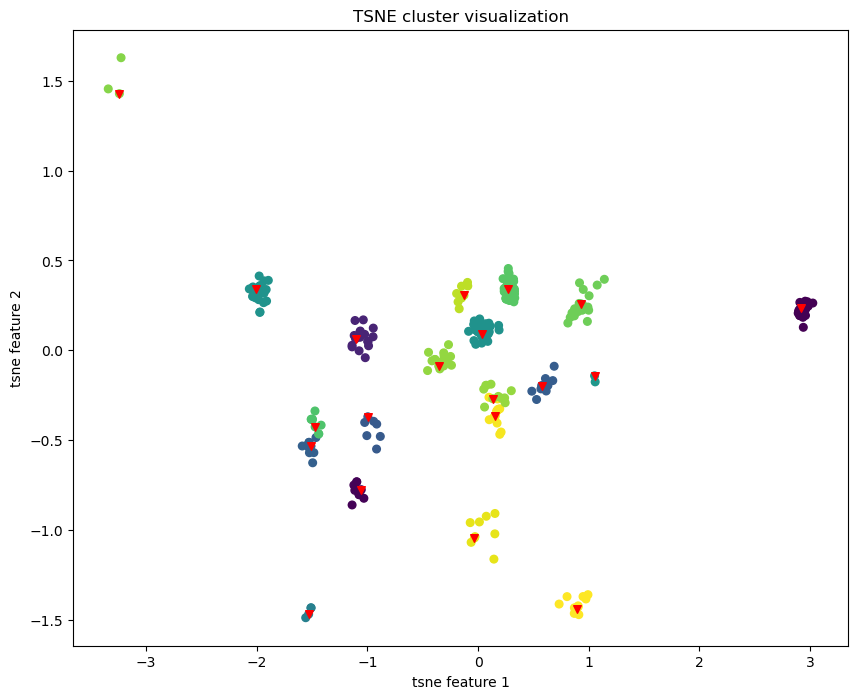

In [65]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import random

randClusters = random.sample(range(0, 999), 20)
print('Clusters sampled: ')
print(randClusters)

subsetDf = centers_df[centers_df['Cluster'].isin(randClusters)]
subsetSoap = subsetDf.drop(columns='Cluster').values

subsetFullDf = df_pca[df_pca['Cluster'].isin(randClusters)]
subsetFullSoap = subsetFullDf.drop(columns='Cluster').values

tsne = TSNE(n_components=2, perplexity=5)
tsneFeatures = tsne.fit_transform(subsetSoap)

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(subsetFullSoap[:, 0], subsetFullSoap[:, 1], s=30, c=subsetFullDf['Cluster'], cmap='viridis')
ax.scatter(subsetSoap[:, 0], subsetSoap[:, 1], s=30, c='red', marker='v')

ax.set_xlabel('tsne feature 1')
ax.set_ylabel('tsne feature 2')
ax.set_title('TSNE cluster visualization')

# Tinkering

In [81]:
restype = set()
type = set()

for index, row in df.iterrows():
    restype.add(row['restype'])

print(f'restypes: {restype}')

counts = df['restype'].value_counts()
print(counts)


restypes: {'HIS', 'MET', 'PHE', 'LEU', 'TRP', 'ASN', 'GLN', 'VAL', 'ARG', 'GLU', 'PCA', 'ASP', 'TYR', 'THR', 'LYS', 'ILE', 'PRO', 'GLY', 'ALA'}
restype
LEU    15803
PHE    12395
TYR    10207
ILE    10124
VAL    10073
TRP     6077
ALA     5473
PRO     2800
THR     2499
LYS     2352
ASP     1802
GLU     1470
GLN     1305
ARG     1144
HIS     1018
MET      936
ASN      783
GLY        1
PCA        1
Name: count, dtype: int64


In [9]:
df.query('restype == "PCA"')

,PDBID,full_PDBID,subdir,resnr,restype,reschain,resnr_lig,restype_lig,reschain_lig,dist,ligcarbonidx,protcarbonidx,ligcoo_x,ligcoo_y,ligcoo_z,protcoo_x,protcoo_y,protcoo_z
6md8_J84_A_602_2_PCA_3_34,6md8,6md8_J84_A_602,pdbbind_opt_sm/,2,PCA,A,1,UNL,Z,3.69,3,34,7.456,-3.878,-13.619,7.365,-1.206,-16.167
